# Векторы и матрицы: одна строка вместо цикла по объектам

ФПМИ.Будущее · ИИ · Прекурс · Занятие 2

На прошлом занятии таблица данных стала массивом NumPy. Сегодня посмотрим на тот же массив как на математический объект: строка — это **вектор**, вся таблица — **матрица**.

К концу занятия вы прочитаете строку `y_pred = X @ w + b` — это линейная модель, которую обучим на занятии 6.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# @title Оформление картинок
from matplotlib.patches import FancyBboxPatch

# Палитра как в занятии 1: axis 0 — синий, axis 1 — фиолетовый, результат — зелёный.
BG, PANEL, TEXT, MUTED = "#0f172a", "#1e293b", "#e5e7eb", "#94a3b8"
BLUE, PURPLE, GREEN, ORANGE, RED = "#60a5fa", "#a78bfa", "#4ade80", "#fb923c", "#f87171"

plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
                     "font.size": 13, "figure.dpi": 130})

def box(ax, x, y, text, color=PANEL, w=1.0, h=0.8, size=17, edge=None, tcolor=TEXT):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                facecolor=color, edgecolor=edge or color, linewidth=2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
            fontsize=size, color=tcolor, fontweight="bold", family="monospace")

def clean(ax, xlim, ylim):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.axis("off")

## 0. Зачем это нужно

### `y_pred = X @ w + b`

Это вся линейная модель. На занятии 6 её обучают на настоящих данных.

**Где встретится:**

- линейные модели — в задачах регионального этапа;
- тексты и картинки превращают в векторы и сравнивают их «похожесть»;
- слой нейросети — это умножение на матрицу.

Разберём её по частям: вектор, скалярное произведение, умножение матрицы на вектор.

## 1. Объект — это вектор, датасет — это матрица

Берём таблицу из занятия 1. Каждая строка `X` — ученик, каждый столбец — предмет.

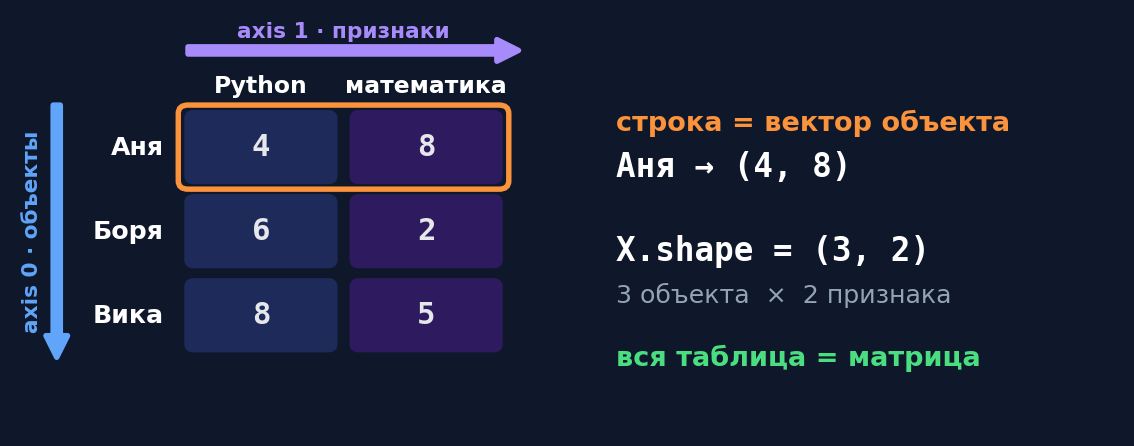

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.2)); clean(ax, (-1.8, 9.6), (-0.6, 4.4))
students, subjects = ["Аня", "Боря", "Вика"], ["Python", "математика"]
scores = [[4, 8], [6, 2], [8, 5]]
for r in range(3):
    ax.text(-0.25, 2.4 - r * 1.0 + 0.4, students[r], ha="right", va="center", fontsize=14, fontweight="bold")
    for c in range(2):
        box(ax, c * 1.7, 2.4 - r * 1.0, str(scores[r][c]), color="#1e2a5a" if c == 0 else "#2e1a5e", w=1.5)
for c in range(2):
    ax.text(c * 1.7 + 0.75, 3.45, subjects[c], ha="center", fontsize=13, fontweight="bold")
ax.annotate("", xy=(3.4, 3.95), xytext=(0, 3.95), arrowprops=dict(color=PURPLE, lw=3))
ax.text(1.6, 4.1, "axis 1 · признаки", color=PURPLE, ha="center", fontsize=12, fontweight="bold")
ax.annotate("", xy=(-1.35, 0.3), xytext=(-1.35, 3.3), arrowprops=dict(color=BLUE, lw=3))
ax.text(-1.6, 1.8, "axis 0 · объекты", color=BLUE, rotation=90, va="center", ha="center", fontsize=12, fontweight="bold")
ax.add_patch(FancyBboxPatch((-0.08, 2.32), 3.36, 0.96, boxstyle="round,pad=0.02,rounding_size=0.1",
                            facecolor="none", edgecolor=ORANGE, linewidth=3))
ax.text(4.4, 3.0, "строка = вектор объекта", color=ORANGE, fontsize=15, fontweight="bold")
ax.text(4.4, 2.45, "Аня → (4, 8)", fontsize=18, family="monospace", fontweight="bold")
ax.text(4.4, 1.45, "X.shape = (3, 2)", fontsize=18, family="monospace", fontweight="bold")
ax.text(4.4, 0.95, "3 объекта  ×  2 признака", color=MUTED, fontsize=14)
ax.text(4.4, 0.2, "вся таблица = матрица", color=GREEN, fontsize=15, fontweight="bold")
plt.show()

In [5]:
# Строки: Аня, Боря, Вика. Столбцы: Python, математика.
names = np.array(["Аня", "Боря", "Вика"])
X = np.array([
    [4, 8],
    [6, 2],
    [8, 5],
])

print("Форма X:", X.shape)
print("Вектор Ани X[0]:", X[0])
print("Признак «математика» X[:, 1]:", X[:, 1])

Форма X: (3, 2)
Вектор Ани X[0]: [4 8]
Признак «математика» X[:, 1]: [8 2 5]


### Вектором можно записать почти что угодно

| Объект | Признаки | Вектор |
| --- | --- | --- |
| ученик | баллы по Python и математике | $(4,\ 8)$ |
| заказ в кофейне | сколько кофе, круассанов, печенья | $(2,\ 1,\ 3)$ |
| герой в игре | сила, ловкость, интеллект | $(9,\ 4,\ 2)$ |
| зритель | оценки трёх фильмов | $(5,\ 1,\ 4)$ |
| картинка 28×28 | яркость каждого пикселя | 784 числа |
| текст | сколько раз встретилось каждое слово | тысячи чисел |

Много объектов — много строк. **Датасет — это матрица: строка — объект, столбец — признак.**

### Вопрос в чат №1

**До запуска:** что вернёт `X[2]`? А `X[:, 1]`? Что означают эти числа?

<details>
<summary>Показать ответ</summary>

`X[2]` — `[8 5]`, строка Вики: 8 по Python, 5 по математике. `X[:, 1]` — `[8 2 5]`, столбец «математика»: баллы всех троих по математике.

</details>

## 2. Скалярное произведение

Математический кружок считает рейтинг так: балл по Python берём один раз, балл по математике — дважды.

### Скалярное произведение

Два вектора **одинаковой длины** → **одно число**: перемножаем попарно и складываем.

$$a \cdot b = a_1 b_1 + a_2 b_2 + \dots + a_n b_n$$

Пример: $(4,\ 8) \cdot (1,\ 2) = 4 \cdot 1 + 8 \cdot 2 = 20$

In [6]:
a = X[0]               # Аня: Python 4, математика 8
w = np.array([1, 2])   # веса математического кружка

print("Поэлементно и сумма:", (a * w).sum())
print("np.dot(a, w):", np.dot(a, w))
print("a @ w:", a @ w)

Поэлементно и сумма: 20
np.dot(a, w): 20
a @ w: 20


### Что означает это число

1. **Взвешенная сумма.** Веса показывают важность каждого признака. Так считает линейная модель.
2. **Длина вектора.** $a \cdot a = |a|^2$, поэтому $|a| = \sqrt{a \cdot a}$.
3. **Угол между векторами.** $a \cdot b = |a| \cdot |b| \cdot \cos\varphi$. Знак числа говорит, в одну ли сторону смотрят векторы.

### Одно действие — разные сюжеты

| Сюжет | Вектор объекта | Вектор весов | Результат |
| --- | --- | --- | --- |
| отбор в кружок | оценки $(4,\ 8)$ | важность предметов $(1,\ 2)$ | рейтинг $20$ |
| кофейня | заказ $(2,\ 1,\ 3)$ | цены $(150,\ 120,\ 50)$ | чек |
| игра | статы героя $(9,\ 4,\ 2)$ | коэффициенты меча $(2,\ 1,\ 0)$ | урон $22$ |
| машинное обучение | признаки $x$ | веса модели $w$ | предсказание $\hat{y}$ |

In [7]:
v = np.array([3, 4])
print("v @ v:", v @ v)
print("Длина np.linalg.norm(v):", np.linalg.norm(v))

v @ v: 25
Длина np.linalg.norm(v): 5.0


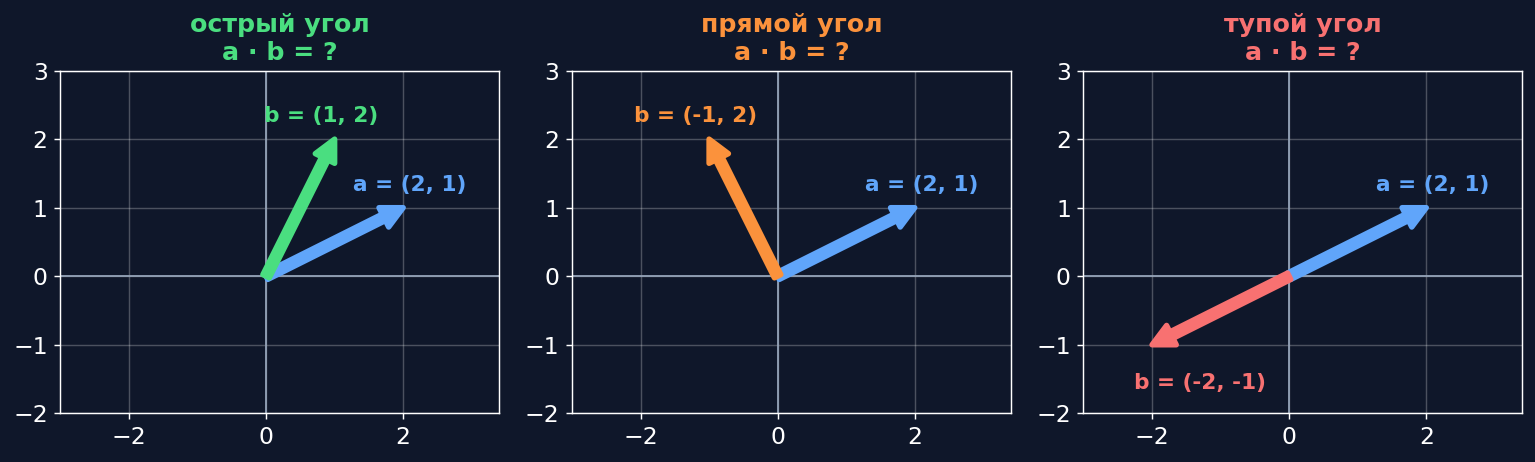

In [8]:
a = np.array([2, 1])
pairs = [(np.array([1, 2]), GREEN, "острый угол"),
         (np.array([-1, 2]), ORANGE, "прямой угол"),
         (np.array([-2, -1]), RED, "тупой угол")]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, (b, color, label) in zip(axes, pairs):
    ax.annotate("", xy=a, xytext=(0, 0), arrowprops=dict(color=BLUE, lw=3))
    ax.annotate("", xy=b, xytext=(0, 0), arrowprops=dict(color=color, lw=3))
    ax.text(a[0] + 0.1, a[1] + 0.25, "a = (2, 1)", color=BLUE, fontsize=12, fontweight="bold", ha="center")
    ax.text(b[0] - 0.2 if b[1] > 0 else b[0] + 0.7, b[1] + (0.25 if b[1] > 0 else -0.65), f"b = ({b[0]}, {b[1]})", color=color, fontsize=12, fontweight="bold", ha="center")
    ax.set_xlim(-3, 3.4); ax.set_ylim(-2, 3); ax.set_aspect("equal"); ax.grid(alpha=0.25)
    ax.axhline(0, color=MUTED, lw=1); ax.axvline(0, color=MUTED, lw=1)
    ax.set_title(f"{label}\na · b = ?", fontsize=14, color=color, fontweight="bold")
plt.tight_layout(); plt.show()

### Пример: у кого вкус похож на твой

Оценки трёх фильмов: боевик, комедия, ужасы. Чем меньше угол между векторами оценок, тем ближе косинус к 1 и тем более похожи вкусы.

$$\cos\varphi = \frac{a \cdot b}{|a| \cdot |b|}$$

In [ ]:
def cosine(a, b):
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

you   = np.array([5, 1, 4])
masha = np.array([4, 2, 5])
petya = np.array([1, 5, 2])

print("Ты и Маша:", round(cosine(you, masha), 2))
print("Ты и Петя:", round(cosine(you, petya), 2))
print("Рекомендуем то, что понравилось Маше.")

Ты и Маша: 0.97
Ты и Петя: 0.51
Рекомендуем то, что понравилось Маше.


### Вопрос в чат №2

$(1,\ 2) \cdot (-2,\ 1) =\ ?$ Что это говорит про векторы?

<details>
<summary>Показать ответ</summary>

$1 \cdot (-2) + 2 \cdot 1 = 0$. Скалярное произведение равно нулю — векторы перпендикулярны.

</details>

### Мини-задача 1. Чек

Заказ: 2 кофе, 1 круассан, 3 печенья — вектор $(2,\ 1,\ 3)$. Цены: $(150,\ 120,\ 50)$. Найдите чек.

<details>
<summary>Показать ответ</summary>

$2 \cdot 150 + 1 \cdot 120 + 3 \cdot 50 = 300 + 120 + 150 = 570$.

</details>

### Мини-задача 2. Перпендикуляр

При каком $t$ векторы $(3,\ t)$ и $(2,\ -1)$ перпендикулярны?

<details>
<summary>Показать ответ</summary>

Перпендикулярны — значит, скалярное произведение равно нулю: $3 \cdot 2 + t \cdot (-1) = 6 - t = 0$, откуда $t = 6$.

</details>

## 3. Матрица на вектор: веса для всех объектов сразу

Рейтинг нужен не только Ане. Можно пройти по строкам циклом, а можно записать одной операцией.

In [9]:
w = np.array([1, 2])   # веса: Python, математика

for i in range(X.shape[0]):
    print(names[i], "→", X[i] @ w)

Аня → 20
Боря → 10
Вика → 18


In [10]:
ratings = X @ w

print("X @ w:", ratings)
print("Форма результата:", ratings.shape)
print("Лучший:", names[ratings.argmax()])
print("С бонусом +5 каждому:", ratings + 5)

X @ w: [20 10 18]
Форма результата: (3,)
Лучший: Аня
С бонусом +5 каждому: [25 15 23]


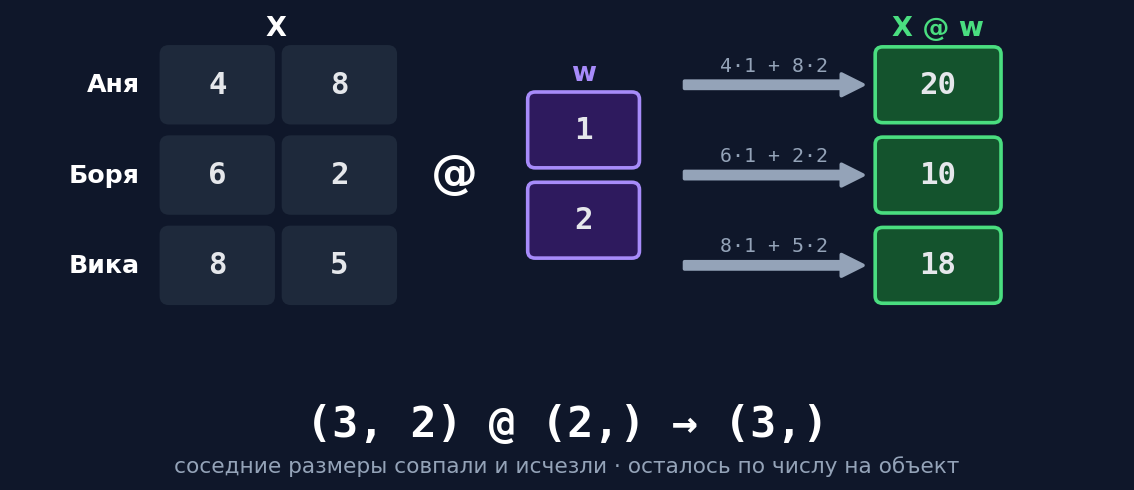

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.6)); clean(ax, (-1.6, 10.2), (-1.5, 3.6))
for r in range(3):
    ax.text(-0.25, 2.4 - r + 0.4, names[r], ha="right", va="center", fontsize=14, fontweight="bold")
    for c in range(2):
        box(ax, c * 1.3, 2.4 - r, str(X[r, c]), w=1.15)
    box(ax, 7.6, 2.4 - r, str(ratings[r]), color="#14532d", edge=GREEN, w=1.3)
    ax.annotate("", xy=(7.45, 2.8 - r), xytext=(5.55, 2.8 - r), arrowprops=dict(color=MUTED, lw=2))
    ax.text(6.5, 2.95 - r, f"{X[r,0]}·1 + {X[r,1]}·2", ha="center", fontsize=11, color=MUTED, family="monospace")
ax.text(3.1, 1.8, "@", fontsize=26, ha="center", va="center", fontweight="bold")
for c in range(2):
    box(ax, 3.9, 1.9 - c, str(w[c]), color="#2e1a5e", edge=PURPLE, w=1.15)
ax.text(1.2, 3.35, "X", fontsize=15, ha="center", fontweight="bold")
ax.text(4.47, 2.85, "w", fontsize=15, ha="center", fontweight="bold", color=PURPLE)
ax.text(8.25, 3.35, "X @ w", fontsize=15, ha="center", fontweight="bold", color=GREEN)
ax.text(4.3, -1.1, "(3, 2) @ (2,) → (3,)", fontsize=24, ha="center", family="monospace", fontweight="bold")
ax.text(4.3, -1.5, "соседние размеры совпали и исчезли · осталось по числу на объект", fontsize=12, ha="center", color=MUTED)
plt.show()

### Это уже машинное обучение

| В нашем примере | В машинном обучении | Обозначение |
| --- | --- | --- |
| ученик | объект | строка $X$ |
| оценки | признаки | столбцы $X$ |
| важность предметов | веса модели | $w$ |
| бонус всем | сдвиг | $b$ |
| рейтинг | предсказание | $\hat{y}$ |

`y_pred = X @ w + b` — **применить веса ко всем объектам сразу.**

In [12]:
w_math = np.array([1, 2])   # математический кружок
w_prog = np.array([2, 1])   # кружок программирования

print("Математика важнее:", X @ w_math, "→ лучший:", names[(X @ w_math).argmax()])
print("Python важнее:    ", X @ w_prog, "→ лучший:", names[(X @ w_prog).argmax()])

Математика важнее: [20 10 18] → лучший: Аня
Python важнее:     [16 14 21] → лучший: Вика


In [13]:
# Строки: Воин, Лучник, Маг. Столбцы: сила, ловкость, интеллект.
heroes = np.array(["Воин", "Лучник", "Маг"])
H = np.array([
    [9, 4, 2],
    [4, 9, 3],
    [3, 4, 9],
])
# Каждый столбец W — своё оружие: меч (2, 1, 0) и посох (0, 1, 2).
W = np.array([
    [2, 0],
    [1, 1],
    [0, 2],
])

damage = H @ W
print("Урон. Строки — герои, столбцы — меч и посох:")
print(damage)
print("Формы:", H.shape, "@", W.shape, "→", damage.shape)

Урон. Строки — герои, столбцы — меч и посох:
[[22  8]
 [17 15]
 [10 22]]
Формы: (3, 3) @ (3, 2) → (3, 2)


In [14]:
try:
    X @ np.array([1, 2, 3])
except ValueError as error:
    print("ValueError:", error)

print()
print("Лечится так — печатаем формы:", X.shape, "и", np.array([1, 2, 3]).shape)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 2)

Лечится так — печатаем формы: (3, 2) и (3,)


### Вопрос в чат №3

**До запуска:** `X` имеет форму `(1000, 7)`. Какой длины должен быть `w`? Какая форма у `X @ w`?

<details>
<summary>Показать ответ</summary>

`w` — длины 7, по весу на каждый признак. `X @ w` — форма `(1000,)`, по одному числу на объект: `(1000, 7) @ (7,) → (1000,)`.

</details>

## 4. Задача: кофейня

### Задача. Кофейня

Цены: кофе — 150, круассан — 120, печенье — 50.

| | кофе | круассан | печенье |
| --- | --- | --- | --- |
| Аня | 2 | 1 | 3 |
| Боря | 1 | 0 | 2 |
| Вика | 0 | 2 | 1 |
| Гоша | 1 | 1 | 1 |

1. Найдите чек каждого.
2. Кто заплатил больше всех?
3. Какая форма у матрицы заказов и у ответа?

Ожидаемая форма ответа: `(4,)`.

In [23]:
customers = np.array(["Аня", "Боря", "Вика", "Гоша"])
C = np.array([
    [2, 1, 3],
    [1, 0, 2],
    [0, 2, 1],
    [1, 1, 1],
])
p = np.array([150, 120, 50])

checks = C @ p

In [24]:
assert checks.shape == (4,)
assert np.array_equal(checks, np.array([570, 250, 290, 320]))

print("Чеки:", checks)
print("Больше всех заплатил(а):", customers[checks.argmax()])
print("Формы:", C.shape, "@", p.shape, "→", checks.shape)
print("С доставкой 50:", checks + 50)
print("Задача: тесты пройдены")

Чеки: [570 250 290 320]
Больше всех заплатил(а): Аня
Формы: (4, 3) @ (3,) → (4,)
С доставкой 50: [620 300 340 370]
Задача: тесты пройдены


## 5. Задача на подумать: секретные веса

До сих пор веса были известны, и мы считали рейтинг. Перевернём задачу: рейтинги известны, а веса — нет.

### Часть 1. Найдите веса

Жюри считает рейтинг по формуле $\text{рейтинг} = a \cdot \text{Python} + b \cdot \text{математика}$, но веса $a$ и $b$ держит в секрете.

Известно: Аня с оценками $(4,\ 8)$ получила рейтинг $20$, Боря с оценками $(6,\ 2)$ — рейтинг $10$.

1. Найдите $a$ и $b$.
2. Проверьте ответ на Вике: у неё оценки $(8,\ 5)$ и рейтинг $18$.

### Часть 2. Неудачная пара

Теперь известны другие двое: Аня $(4,\ 8)$ с рейтингом $20$ и Гоша $(2,\ 4)$ с рейтингом $10$.

1. Попробуйте найти веса. Что пошло не так?
2. Проверьте, что веса $(1,\ 2)$, $(3,\ 1)$ и $(5,\ 0)$ подходят обоим. Какой рейтинг каждая из этих «моделей» предскажет Вике?

### Часть 3. Лишний признак

В таблицу добавили третий столбец — сумму баллов: Аня $(4,\ 8,\ 12)$, Боря $(6,\ 2,\ 8)$, Вика $(8,\ 5,\ 13)$.

1. Проверьте, что веса $(1,\ 2,\ 0)$ и $(0,\ 1,\ 1)$ дают всем троим одинаковые рейтинги.
2. Почему так вышло? Найдите ещё один такой набор весов.
3. Можно ли теперь ответить на вопрос «что для жюри важнее — Python или математика»?

### Чего мы хотим от матрицы признаков

Хорошая матрица — та, по которой веса находятся **однозначно**.

- **Объектов не меньше, чем признаков.** Каждый объект — одно уравнение, каждый вес — одно неизвестное.
- **Объекты разные.** Строки не повторяют друг друга и не отличаются просто в несколько раз.
- **Признаки не дублируют друг друга.** Ни один столбец не выражается через остальные.
- **Признаки в сопоставимом масштабе.** Иначе веса нельзя сравнивать между собой — для этого была стандартизация на прошлом занятии.

### Бонус. Граница отбора

Математический кружок берёт всех, у кого $1 \cdot \text{Python} + 2 \cdot \text{математика} \ge 20$.

1. Отметьте на плоскости (Python, математика) всех, у кого рейтинг **ровно** 20. Что это за фигура?
2. Как она расположена относительно вектора весов $w = (1,\ 2)$?
3. С какой стороны от неё те, кого берут?

**Ответы к задаче «Секретные веса»**

<details>
<summary>Показать ответы</summary>

- **Часть 1.** $a = 1,\ b = 2$. Проверка на Вике: $8 + 10 = 18$.
- **Часть 2.** Второе уравнение — это первое, поделённое на 2, поэтому решений бесконечно много: $a = 5 - 2b$. Вике модели $(1, 2)$, $(3, 1)$, $(5, 0)$ предскажут $18$, $29$ и $40$.
- **Часть 3.** Третий столбец — сумма первых двух. Подходит любой набор $(1 - c,\ 2 - c,\ c)$, например $(-1,\ 0,\ 2)$. По весам судить о важности признаков уже нельзя.
- **Бонус.** Это прямая $P + 2M = 20$. Она перпендикулярна вектору весов $(1,\ 2)$; берут тех, кто с той стороны, куда он показывает.

</details>

## 6. Главное после урока

### Шпаргалка занятия

```python
a @ b                   # скалярное произведение: попарно перемножить и сложить
np.linalg.norm(a)       # длина вектора
X @ w + b               # предсказания для всех объектов сразу

# формы: (n, d) @ (d,) → (n,)
```

- **Объект — вектор, датасет — матрица:** строка — объект, столбец — признак.
- **Скалярное произведение — взвешенная сумма.** Его знак говорит, в одну ли сторону смотрят векторы; ноль — перпендикулярны.
- **`X @ w + b`** считает предсказания для всех объектов сразу. Соседние размеры обязаны совпасть.